# Figure 12: population comparison of decoded samples against the data

Section 4.7, `fig:latent_data_hists`. A population-level comparison
between the data surfaces and surfaces generated by decoding latents
drawn from the aggregate encoded distribution: spot filling factor,
total variation, and spot distribution entropy. The Section 6.4 metric
register also asks for the split KL on these summaries, which the
final cell prints with the Jensen-Shannon divergence.

The data population is every surface in the holdout, all 100,000 of
them; the training marginals are the same distribution by
construction, seed streams aside. One aggregate-posterior draw per
surface is decoded, as in figure 11. The metrics follow the package
conventions rather than the legacy VAE notebooks: the spot threshold
is the absolute 0.9 every detection metric uses, and the total
variation's periodic gradient uses the package grid spacing. Both
departures are stated in the metric docstrings.

The pass is chunked and cached, so re-running this notebook is
immediate.

## Imports

In [1]:
import torch

from _setup import *

from starspot_sbi.pipeline import decode_latents, encode_latents

## Setup

The three summaries the panels compare, the chunk size the pass works
in, and the ink each panel takes.

In [2]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CHUNK = 2000               # surfaces held in memory at once
SUMMARIES = (('sff', 'Spot Filling Factor', BLUE),
             ('tv', 'Total Variation', RED),
             ('ent', 'Spot Distribution Entropy', GREEN))
N_BINS = 60
CACHE = os.path.join(CACHES, 'fig12_latent_data_hists.npz')

## Selecting the sample

Every surface in the holdout index.

In [3]:
idx = load_meta().index.values
print(f'{len(idx):,} holdout surfaces, the whole set')

100,000 holdout surfaces, the whole set


## Inference

Decodes one aggregate-posterior draw per surface and takes the three
summaries over both populations, one chunk in memory at a time: the
holdout is 100,000 surfaces and two render sets would not fit
otherwise. The generator is created once outside the loop, so the
draws are a single deterministic stream at `SEED` for a given
`CHUNK`.

In [4]:
def score_all():
    """The three summaries over both populations, for the whole holdout."""
    rng = np.random.default_rng(SEED)
    vae, stats = load_autoencoder(device=DEVICE)
    w_full = metrics.weights(0.0, *GRID, kind='full')
    out = {f'{pop}_{key}': np.empty(len(idx))
           for pop in ('data', 'decoded') for key, _, _ in SUMMARIES}
    for a in range(0, len(idx), CHUNK):
        b = min(a + CHUNK, len(idx))
        coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                                f'surface_{i:07d}.npy'))
                           for i in idx[a:b]])
        truth_real = np.stack([coeffs_to_real(c) for c in coeffs])
        mu, sigma = encode_latents(coeffs, vae, stats, device=DEVICE)
        z = mu + sigma * rng.standard_normal(mu.shape).astype(np.float32)
        gen_imgs = render_draws(decode_latents(z, vae, stats, device=DEVICE),
                                device=DEVICE)
        timgs = render_draws(truth_real, device=DEVICE)
        for pop, imgs in (('data', timgs), ('decoded', gen_imgs)):
            out[f'{pop}_sff'][a:b] = [
                metrics.wmean(metrics.spot_mask(im), w_full) for im in imgs]
            out[f'{pop}_tv'][a:b] = [
                metrics.total_variation(im) for im in imgs]
            out[f'{pop}_ent'][a:b] = [
                metrics.spot_distribution_entropy(im) for im in imgs]
        print(f'  {b:,} / {len(idx):,}', flush=True)
    return dict(idx=idx, seed=SEED, chunk=CHUNK, vae=VAE_TAG + WEIGHTS_SUFFIX,
                **out)


os.makedirs(CACHES, exist_ok=True)
z = np.load(CACHE) if os.path.exists(CACHE) else None
# The guard checks the scored population, not just that a file is there, so a
# different holdout or sample size recomputes instead of being silently reused.
# SEED and CHUNK are part of the cache identity too: one generator feeds the
# whole pass, so the latent draws depend on where the chunk boundaries fall.
# So is the checkpoint: swapping the weights leaves every other key intact and
# would otherwise plot stale latents against fresh data.
if (z is not None and z['data_sff'].size == len(idx)
        and np.array_equal(z['idx'], idx)
        and int(z['seed']) == SEED and int(z['chunk']) == CHUNK
        and str(z['vae']) == VAE_TAG + WEIGHTS_SUFFIX):
    d = {k: z[k] for k in z.files}
    print(f'summaries read from {os.path.relpath(CACHE, REPO)}')
else:
    d = score_all()                 # the whole holdout; tens of minutes
    np.savez(CACHE, **d)
    print(f'summaries written to {os.path.relpath(CACHE, REPO)}')

summary = {pop: {key: d[f'{pop}_{key}'] for key, _, _ in SUMMARIES}
           for pop in ('data', 'decoded')}
print(f'{len(idx):,} surfaces, one aggregate-posterior decode each, '
      f'seed {SEED}, chunk {CHUNK:,}, checkpoint '
      f'{VAE_TAG}{WEIGHTS_SUFFIX}')

summaries read from caches/fig12_latent_data_hists.npz
100,000 surfaces, one aggregate-posterior decode each, seed 0, chunk 2,000, checkpoint n640000_seed101_temp


In [5]:
divergence = {key: metrics.hist_kl_split(summary['data'][key],
                                         summary['decoded'][key])
              for key, _, _ in SUMMARIES}
print('divergences done')

divergences done


## Plotting

Draws the figure from the names bound above.

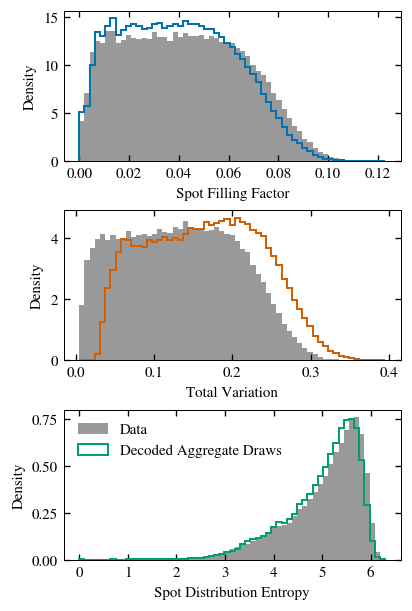

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(COL, COL * 1.5))
for ax, (key, lab, ink) in zip(axes, SUMMARIES):
    a, b = summary['data'][key], summary['decoded'][key]
    bins = np.linspace(np.nanmin([np.nanmin(a), np.nanmin(b)]),
                       np.nanmax([np.nanmax(a), np.nanmax(b)]), N_BINS)
    ax.hist(a[np.isfinite(a)], bins=bins, color='0.6', density=True,
            label='Data')
    ax.hist(b[np.isfinite(b)], bins=bins, histtype='step', lw=1.2,
            color=ink, density=True,
            label='Decoded Aggregate Draws')
    ax.set_xlabel(lab)
    ax.set_ylabel('Density')
# Bottom panel, upper left: the entropy distributions run up against the
# right-hand edge, so the top-left corner is the one reliably empty patch
# in the figure and the legend sits clear of both histograms there.
axes[2].legend(loc='upper left')

## Saving and caption numbers

Writes the pdf and png, then prints the numbers the Section 4.7 text
quotes: the filling-factor deficit at the high end, the entropy shift
and the total-variation displacement, each localised by the split KL.

In [7]:
save_fig(fig, 'fig12_latent_data_hists')
for key, lab, _ in SUMMARIES:
    r = divergence[key]
    data, decoded = summary['data'][key], summary['decoded'][key]
    print(f'{lab}: KL {r["kl_total"]:.4f} (left of the data median '
          f'{r["kl_left"]:.4f}, right {r["kl_right"]:.4f}), '
          f'JS {r["js"]:.4f}')
    print(f'  data median {np.nanmedian(data):.4f}, decoded '
          f'{np.nanmedian(decoded):.4f}; data 95th '
          f'{np.nanpercentile(data, 95):.4f}, decoded '
          f'{np.nanpercentile(decoded, 95):.4f}')
n_data = int(np.isnan(summary['data']['ent']).sum())
n_decoded = int(np.isnan(summary['decoded']['ent']).sum())
print(f'immaculate surfaces (entropy undefined): {n_data:,} data, '
      f'{n_decoded:,} decoded')

wrote notebooks/paper/figs/fig12_latent_data_hists.pdf, notebooks/paper/figs/fig12_latent_data_hists.png
Spot Filling Factor: KL 0.0134 (left of the data median -0.0306, right 0.0439), JS 0.0031
  data median 0.0414, decoded 0.0390; data 95th 0.0819, decoded 0.0773
Total Variation: KL 1.4060 (left of the data median 1.5044, right -0.0984), JS 0.0435
  data median 0.1324, decoded 0.1661; data 95th 0.2516, decoded 0.2808
Spot Distribution Entropy: KL 0.0154 (left of the data median -0.0308, right 0.0462), JS 0.0036
  data median 5.2531, decoded 5.1943; data 95th 5.9185, decoded 5.8586
immaculate surfaces (entropy undefined): 106 data, 478 decoded
